# 04 — Features multimodales, fusion et résultats finaux

Jusqu'ici, seule la description était utilisée. Ce notebook ajoute les autres colonnes du dataset, compare deux façons
de les combiner (**concaténation** vs **stacking**), mesure l'apport de chaque source (**ablation**) et présente
l'évaluation finale sur le test, comparée à un LLM *zero-shot*.

| Bloc | Colonne | Représentation | Dimension |
|---|---|---|---|
| `description` | `prob_desc_description` | Sentence-BERT `all-mpnet-base-v2` | 768 |
| `input_spec` | `prob_desc_input_spec` | Sentence-BERT | 768 |
| `notes` | `prob_desc_notes` | Sentence-BERT | 768 |
| `code` | `source_code` | **UniXcoder** (`microsoft/unixcoder-base`, encodeur pré-entraîné sur du code) | 768 |
| `difficulty` | `difficulty` | 5 tranches de quantiles + « inconnue » (one-hot) | 6 |
| `tfidf_desc` | `prob_desc_description` | TF-IDF de la description lemmatisée | ~1 800 (creux) |
| `tfidf_code` | `source_code` | TF-IDF des identifiants Python | ~1 700 (creux) |

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from iterstrat.ml_stratifiers import (
    MultilabelStratifiedKFold,
    MultilabelStratifiedShuffleSplit,
)
from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    hamming_loss,
    jaccard_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import cross_val_predict
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 140)

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 23:12:40.777000 75811 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Paramètres

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks_prod" else Path.cwd()
DATA_PATH = ROOT / "data" / "processed" / "clean.parquet"
EMBEDDINGS_DIR = ROOT / "data" / "embeddings"
LLM_PREDICTIONS_PATH = ROOT / "data" / "llm" / "gemini-3.1-flash-lite__test.jsonl"

TAGS = ["math", "graphs", "strings", "number theory", "trees", "geometry", "games", "probabilities"]
SEED = 42
N_FOLDS = 5
N_BOOTSTRAP = 1000
THRESHOLD_GRID = np.arange(0.05, 0.96, 0.01)

TEXT_MODEL = "sentence-transformers/all-mpnet-base-v2"
CODE_MODEL = "microsoft/unixcoder-base"
CODE_MAX_TOKENS = 1024  # 9 % des codes tronqués à 1 024 tokens, contre 25 % à 512 (section 1)
DIFFICULTY_BINS = 5

# TF-IDF : mêmes réglages qu'au notebook 02 (C choisi en CV)
CODE_TOKEN_PATTERN = r"[A-Za-z_][A-Za-z0-9_]+|\d{2,}"
CODE_STOP_WORDS = [
    "False", "None", "True", "and", "as", "assert", "async", "await", "break", "class", "continue", "def", "del",
    "elif", "else", "except", "finally", "for", "from", "global", "if", "import", "in", "is", "lambda", "nonlocal",
    "not", "or", "pass", "raise", "return", "try", "while", "with", "yield",
    "sys", "stdin", "stdout", "readline", "input", "raw_input", "print", "write", "flush", "os", "io", "self",
]  # fmt: skip
TFIDF_DESC_C, TFIDF_CODE_C = 1.0, 0.3

## Données

In [3]:
df = pd.read_parquet(DATA_PATH)
Y = np.array([[tag in tags for tag in TAGS] for tags in df["tags"]], dtype=int)

split = df["split"].to_numpy()
train, val, test, dev = split == "train", split == "val", split == "test", split != "test"
test_df = df[test]
Y_train, Y_val, Y_test, Y_dev = Y[train], Y[val], Y[test], Y[dev]

## 1. Construction des blocs de features

### Embeddings

Un embedding par champ texte plutôt qu'un seul sur le texte concaténé : un encodeur tronque au-delà de 384 tokens
(Sentence-BERT), on perdrait la fin de l'énoncé. Le code garde sa casse et sa ponctuation, qui ont du sens pour UniXcoder.
Les embeddings sont mis en cache (le code prend plusieurs minutes à encoder).

In [4]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"


def cached_embeddings(texts: pd.Series, model_name: str, cache_name: str, batch_size: int = 32, max_len: int | None = None) -> np.ndarray:
    """Même fonction qu'au notebook 02 : embeddings normalisés L2, relus depuis le cache s'il correspond."""
    path = EMBEDDINGS_DIR / f"{model_name.split('/')[-1]}__{cache_name}.npz"
    if path.exists():
        cache = np.load(path)
        if str(cache["model"]) == model_name and np.array_equal(cache["sample_id"], texts.index):
            return cache["embeddings"]

    encoder = SentenceTransformer(model_name, device=device)
    if max_len:
        encoder.max_seq_length = max_len
    embeddings = encoder.encode(texts.tolist(), batch_size=batch_size, normalize_embeddings=True, show_progress_bar=True)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(path, embeddings=embeddings, sample_id=texts.index.to_numpy(), model=model_name)
    return embeddings


blocks = {
    "description": cached_embeddings(df["text_clean"], TEXT_MODEL, "prob_desc_description"),
    "input_spec": cached_embeddings(df["input_spec_clean"], TEXT_MODEL, "prob_desc_input_spec"),
    "notes": cached_embeddings(df["notes_clean"], TEXT_MODEL, "prob_desc_notes"),
    "code": cached_embeddings(df["source_code"], CODE_MODEL, "source_code", batch_size=16, max_len=CODE_MAX_TOKENS),
    # Blocs bruts : leur transformation (tranches, vocabulaire TF-IDF) est apprise dans le modèle, sur le train uniquement
    "difficulty": df[["difficulty"]].to_numpy(dtype=float),
    "tfidf_desc": df["text_lemma"].to_numpy(),
    "tfidf_code": df["source_code"].to_numpy(),
}
DENSE_BLOCKS = ["description", "input_spec", "notes", "code", "difficulty"]
pd.Series({name: block.shape[1] if block.ndim == 2 else "texte → TF-IDF" for name, block in blocks.items()}, name="colonnes").to_frame().T

,description,input_spec,notes,code,difficulty,tfidf_desc,tfidf_code
colonnes,768,768,768,768,1,texte → TF-IDF,texte → TF-IDF


In [5]:
# Pourquoi 1 024 tokens pour UniXcoder : part des codes tronqués selon la longueur maximale
code_tokenizer = SentenceTransformer(CODE_MODEL, device=device).tokenizer
code_lengths = pd.Series([len(ids) for ids in code_tokenizer(df["source_code"].tolist())["input_ids"]])
print(f"Codes tronqués à 512 tokens : {(code_lengths > 512).mean():.1%} | à 1024 : {(code_lengths > 1024).mean():.1%} "
      f"(médiane {code_lengths.median():.0f} tokens)")
print(f"input_spec vide : {(df['input_spec_clean'] == '').mean():.1%} | notes vides : {(df['notes_clean'] == '').mean():.1%}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 64672.75it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1183 > 1026). Running this sequence through the model will result in indexing errors


Codes tronqués à 512 tokens : 25.4% | à 1024 : 8.8% (médiane 281 tokens)
input_spec vide : 0.7% | notes vides : 27.1%


### Difficulté

La difficulté est un nombre (800 à 3 500) avec des valeurs inconnues (NaN ou `-1`). Plutôt que de l'imputer, on la
découpe en 5 tranches de même effectif (bornes apprises sur les données d'entraînement) plus une tranche « inconnue »,
puis on l'encode en one-hot : la relation tag / difficulté n'a pas à être linéaire.

In [6]:
class DifficultyEncoder(BaseEstimator, TransformerMixin):  # héritage : utilisable dans un pipeline sklearn
    """One-hot de la difficulté : DIFFICULTY_BINS tranches de quantiles + une colonne « inconnue »."""

    def fit(self, X: np.ndarray, y=None) -> "DifficultyEncoder":
        values = X[:, 0]
        known = values[values > 0]  # NaN > 0 est faux : NaN et -1 sont exclus
        self.edges_ = np.quantile(known, np.linspace(0, 1, DIFFICULTY_BINS + 1)[1:-1])
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        values = X[:, 0]
        unknown = ~(values > 0)
        column = np.where(unknown, DIFFICULTY_BINS, np.digitize(np.nan_to_num(values), self.edges_))
        return np.eye(DIFFICULTY_BINS + 1)[column]


difficulty_encoder = DifficultyEncoder().fit(blocks["difficulty"][train])
print("Bornes des tranches (apprises sur train) :", difficulty_encoder.edges_)
print("Effectif par tranche (train) :", difficulty_encoder.transform(blocks["difficulty"][train]).sum(axis=0).astype(int))

Bornes des tranches (apprises sur train) : [1100. 1500. 1800. 2200.]
Effectif par tranche (train) : [564 682 654 761 686  36]


## 2. Deux façons de combiner les blocs

**Concaténation** : on colle les blocs denses côte à côte (~3 000 colonnes), on standardise chaque colonne (pour que la
pénalité $L_2$ traite toutes les dimensions de la même façon), puis 8 régressions logistiques avec un seul `C`.

**Stacking** (deux niveaux) :
- *Niveau 1* : un modèle par bloc (régression logistique ; TF-IDF et difficulté ont leur propre transformation).
- *Niveau 2* : pour chaque tag, une régression logistique qui prend en entrée les **logits** des modèles de niveau 1
  pour ce tag, et apprend quel bloc croire pour quel tag.
- Le niveau 2 est entraîné sur des prédictions **out-of-fold** : chaque prédiction de niveau 1 est faite par un modèle
  qui n'a pas vu l'exemple. Sinon, le niveau 2 ferait trop confiance aux blocs qui sur-apprennent.

Le stacking permet aussi d'ajouter les TF-IDF (matrices creuses de ~1 800 colonnes) sans les mélanger aux embeddings.

In [7]:
def logistic(C: float = 1.0) -> OneVsRestClassifier:
    return OneVsRestClassifier(LogisticRegression(C=C, class_weight="balanced", max_iter=2000))


def block_model(name: str):
    """Modèle de niveau 1 d'un bloc."""
    if name == "difficulty":
        return make_pipeline(DifficultyEncoder(), logistic())
    if name == "tfidf_desc":
        return make_pipeline(TfidfVectorizer(stop_words="english", min_df=10, sublinear_tf=True), logistic(TFIDF_DESC_C))
    if name == "tfidf_code":
        vectorizer = TfidfVectorizer(token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS, min_df=5, sublinear_tf=True)
        return make_pipeline(vectorizer, logistic(TFIDF_CODE_C))
    return logistic()  # embeddings


def logit(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


class ConcatModel(BaseEstimator):
    """Blocs denses concaténés → standardisation → 8 régressions logistiques."""

    def __init__(self, names: list[str], C: float):
        self.names, self.C = names, C

    def _features(self, blocks: dict) -> np.ndarray:
        parts = [self.difficulty_.transform(blocks[n]) if n == "difficulty" else blocks[n] for n in self.names]
        return np.hstack(parts)

    def fit(self, blocks: dict, Y: np.ndarray) -> "ConcatModel":
        if "difficulty" in self.names:
            self.difficulty_ = DifficultyEncoder().fit(blocks["difficulty"])
        self.model_ = make_pipeline(StandardScaler(), logistic(self.C)).fit(self._features(blocks), Y)
        return self

    def predict_proba(self, blocks: dict) -> np.ndarray:
        return self.model_.predict_proba(self._features(blocks))


class StackingModel(BaseEstimator):
    """Niveau 1 : un modèle par bloc. Niveau 2 : par tag, une régression logistique sur les logits out-of-fold."""

    def __init__(self, names: list[str]):
        self.names = names

    def fit(self, blocks: dict, Y: np.ndarray) -> "StackingModel":
        inner_folds = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
        # oof[:, b, k] : probabilité out-of-fold du tag k selon le bloc b
        oof = np.stack(
            [cross_val_predict(block_model(n), blocks[n], Y, cv=inner_folds, method="predict_proba") for n in self.names], axis=1
        )
        self.block_models_ = {n: block_model(n).fit(blocks[n], Y) for n in self.names}
        self.meta_models_ = [
            LogisticRegression(class_weight="balanced").fit(logit(oof[:, :, k]), Y[:, k]) for k in range(Y.shape[1])
        ]
        return self

    def predict_proba(self, blocks: dict) -> np.ndarray:
        probas = np.stack([self.block_models_[n].predict_proba(blocks[n]) for n in self.names], axis=1)
        return np.column_stack([meta.predict_proba(logit(probas[:, :, k]))[:, 1] for k, meta in enumerate(self.meta_models_)])

### Validation croisée

Mêmes règles qu'aux notebooks précédents : 5 folds stratifiés sur train + val, critère Macro-AP.

In [8]:
def rows(blocks: dict, mask_or_idx) -> dict:
    """Sous-ensemble de lignes de chaque bloc."""
    return {name: block[mask_or_idx] for name, block in blocks.items()}


dev_blocks = rows(blocks, dev)
folds = list(MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(Y_dev)), Y_dev))


def cross_val_macro_ap(model) -> tuple[float, float]:
    """`clone` repart d'un modèle vierge à chaque fold (d'où l'héritage de BaseEstimator)."""
    scores = []
    for train_idx, eval_idx in folds:
        fitted = clone(model).fit(rows(dev_blocks, train_idx), Y_dev[train_idx])
        proba = fitted.predict_proba(rows(dev_blocks, eval_idx))
        scores.append(average_precision_score(Y_dev[eval_idx], proba, average="macro"))
    return np.mean(scores), np.std(scores)


# Régularisation de la concaténation : avec ~3 000 colonnes standardisées, il faut un C petit
concat_C = pd.DataFrame(
    {C: cross_val_macro_ap(ConcatModel(DENSE_BLOCKS, C)) for C in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1)},
    index=["cv_macro_ap", "cv_std"],
).T.rename_axis("C")
BEST_CONCAT_C = concat_C["cv_macro_ap"].idxmax()
print("C retenu pour la concaténation :", BEST_CONCAT_C)
concat_C.round(4)

C retenu pour la concaténation : 0.001


,cv_macro_ap,cv_std
C,,
0.0001,0.6467,0.0350
0.0003,0.6576,0.0327
0.0010,0.6609,0.0298
0.0030,0.6544,0.0277
0.0100,0.6379,0.0242
0.0300,0.6238,0.0206
0.1000,0.6118,0.0211


## 3. Ablation : que rapporte chaque bloc ?

Trois lectures complémentaires :
- **seul** : le bloc utilisé sans les autres ;
- **cumulatif** : on ajoute les blocs un à un ;
- **retrait** : tous les blocs sauf un (ce que l'on perd sans lui).

Ablation terminée en 53 s


fusion                   concat  stacking
type      blocs                          
seul      description    0.5914    0.5902
          input_spec     0.4056    0.4067
          notes          0.3734    0.3768
          code           0.4044    0.4051
          difficulty     0.1125    0.1117
cumulatif + description  0.5914    0.5902
          + input_spec   0.6162    0.6090
          + notes        0.6173    0.6137
          + code         0.6594    0.6583
          + difficulty   0.6609    0.6583
retrait   - description  0.5749    0.5744
          - input_spec   0.6544    0.6554
          - notes        0.6608    0.6582
          - code         0.6200    0.6200
          - difficulty   0.6594    0.6583

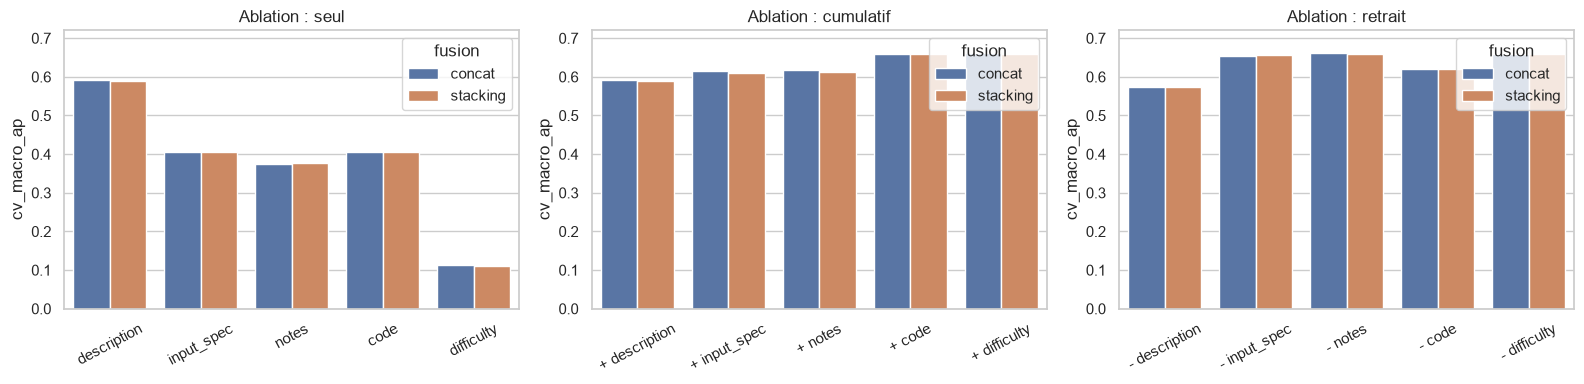

In [9]:
def make_fusion(fusion: str, names: list[str]):
    return ConcatModel(names, BEST_CONCAT_C) if fusion == "concat" else StackingModel(names)


experiments = (
    [("seul", b, [b]) for b in DENSE_BLOCKS]
    + [("cumulatif", "+ " + DENSE_BLOCKS[i], DENSE_BLOCKS[: i + 1]) for i in range(len(DENSE_BLOCKS))]
    + [("retrait", "- " + b, [x for x in DENSE_BLOCKS if x != b]) for b in DENSE_BLOCKS]
)

start = time.perf_counter()
ablation = pd.DataFrame(
    [
        {"type": kind, "blocs": label, "fusion": fusion, "cv_macro_ap": cross_val_macro_ap(make_fusion(fusion, names))[0]}
        for kind, label, names in experiments
        for fusion in ("concat", "stacking")
    ]
)
print(f"Ablation terminée en {time.perf_counter() - start:.0f} s")
display(ablation.pivot_table(index=["type", "blocs"], columns="fusion", values="cv_macro_ap", sort=False).round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, kind in zip(axes, ["seul", "cumulatif", "retrait"]):
    sns.barplot(data=ablation[ablation["type"] == kind], x="blocs", y="cv_macro_ap", hue="fusion", ax=ax)
    ax.set(title=f"Ablation : {kind}", xlabel="", ylim=(0, 0.72))
    ax.tick_params(axis="x", rotation=28)
plt.tight_layout()
plt.show()

**Ajout des TF-IDF au stacking** : la TF-IDF de description apporte-t-elle un signal lexical que les embeddings diluent ?

In [10]:
tfidf_variants = {
    "embeddings + difficulté": DENSE_BLOCKS,
    "+ tfidf_desc": DENSE_BLOCKS + ["tfidf_desc"],
    "+ tfidf_code": DENSE_BLOCKS + ["tfidf_code"],
    "+ tfidf_desc + tfidf_code": DENSE_BLOCKS + ["tfidf_desc", "tfidf_code"],
}
tfidf_ablation = pd.DataFrame(
    {label: cross_val_macro_ap(StackingModel(names)) for label, names in tfidf_variants.items()},
    index=["cv_macro_ap", "cv_std"],
).T
BEST_VARIANT = tfidf_ablation["cv_macro_ap"].idxmax()
print("Variante retenue :", BEST_VARIANT)
tfidf_ablation.round(4)

Variante retenue : + tfidf_desc


,cv_macro_ap,cv_std
embeddings + difficulté,0.6583,0.0263
+ tfidf_desc,0.6714,0.0276
+ tfidf_code,0.6571,0.0214
+ tfidf_desc + tfidf_code,0.6683,0.0251


## 3 bis. Un MLP sur les blocs multimodaux

Au notebook 03, le MLP sur la description seule restait sous la régression logistique (0,593 contre 0,612 de
Macro-F1). Mais il n'avait accès qu'à une source. Sur les blocs multimodaux, sa couche cachée peut capter des
**interactions entre sources** (par exemple un énoncé sur des nombres et `gcd` dans le code), ce que la
concaténation linéaire et le stacking ne font pas.

- **Entrée** : les mêmes blocs denses que la concaténation (~3 000 colonnes standardisées).
- **Réseau** : celui du notebook 03, `entrée → 256 → ReLU → Dropout → 8`, avec `pos_weight` pour la rareté des tags.
- **Early stopping** sur 15 % du jeu d'entraînement, jamais sur le jeu évalué ni sur val (réservé aux seuils).
- **Moyenne de 5 graines** : le MLP du notebook 03 variait de ±0,013 de Macro-F1 selon sa graine ; on moyenne les
  probabilités de 5 réseaux pour réduire cette variance.
- **Hyperparamètres** : la meilleure configuration du notebook 03 (`lr=3e-3`, `dropout=0.5`), en faisant varier
  seulement `weight_decay`, dont l'optimum était au bord de la grille.

**Règle de décision, fixée avant de lancer** : le MLP ne remplace le stacking que s'il le dépasse en CV d'au moins un
écart-type entre folds (≈ 0,027 de Macro-AP).

In [11]:
class MLP(nn.Module):
    def __init__(self, input_dim: int, dropout: float, hidden: int = 256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, len(TAGS)))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)  # logits ; la sigmoïde est dans la loss et à la prédiction


def train_mlp(X, Y, X_stop, Y_stop, lr, weight_decay, dropout, seed, max_epochs=200, patience=15) -> MLP:
    """Même entraînement qu'au notebook 03 : renvoie le réseau à son epoch de loss minimale sur X_stop."""
    torch.manual_seed(seed)
    X, Y = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
    X_stop, Y_stop = torch.tensor(X_stop, dtype=torch.float32), torch.tensor(Y_stop, dtype=torch.float32)

    model = MLP(X.shape[1], dropout)
    positives = Y.sum(dim=0).clamp(min=1)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=(len(Y) - positives) / positives)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_loss, best_state, best_epoch = float("inf"), None, 0
    for epoch in range(max_epochs):
        model.train()
        for batch in torch.randperm(len(X)).split(64):
            optimizer.zero_grad()
            loss_fn(model(X[batch]), Y[batch]).backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            stop_loss = loss_fn(model(X_stop), Y_stop).item()
        if stop_loss < best_loss:
            best_loss, best_epoch = stop_loss, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if epoch - best_epoch >= patience:
            break

    model.load_state_dict(best_state)
    return model


class MultimodalMLP(BaseEstimator):
    """Blocs denses concaténés → standardisation → moyenne de `n_seeds` MLP (même interface que les fusions)."""

    def __init__(self, names: list[str], lr: float = 3e-3, weight_decay: float = 1.0, dropout: float = 0.5, n_seeds: int = 5):
        self.names, self.lr, self.weight_decay, self.dropout, self.n_seeds = names, lr, weight_decay, dropout, n_seeds

    def _features(self, blocks: dict) -> np.ndarray:
        parts = [self.difficulty_.transform(blocks[n]) if n == "difficulty" else blocks[n] for n in self.names]
        return self.scaler_.transform(np.hstack(parts))

    def fit(self, blocks: dict, Y: np.ndarray) -> "MultimodalMLP":
        if "difficulty" in self.names:
            self.difficulty_ = DifficultyEncoder().fit(blocks["difficulty"])
        raw = [self.difficulty_.transform(blocks[n]) if n == "difficulty" else blocks[n] for n in self.names]
        self.scaler_ = StandardScaler().fit(np.hstack(raw))
        X = self._features(blocks)

        # 15 % du jeu d'entraînement pour l'early stopping, stratifié sur les tags
        splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
        fit_idx, stop_idx = next(splitter.split(X, Y))
        params = {"lr": self.lr, "weight_decay": self.weight_decay, "dropout": self.dropout}
        self.nets_ = [
            train_mlp(X[fit_idx], Y[fit_idx], X[stop_idx], Y[stop_idx], seed=seed, **params) for seed in range(self.n_seeds)
        ]
        return self

    def predict_proba(self, blocks: dict) -> np.ndarray:
        X = torch.tensor(self._features(blocks), dtype=torch.float32)
        with torch.no_grad():
            return np.mean([torch.sigmoid(net.eval()(X)).numpy() for net in self.nets_], axis=0)

In [12]:
start = time.perf_counter()
mlp_grid = pd.DataFrame(
    {wd: cross_val_macro_ap(MultimodalMLP(DENSE_BLOCKS, weight_decay=wd)) for wd in (0.3, 1.0, 3.0)},
    index=["cv_macro_ap", "cv_std"],
).T.rename_axis("weight_decay")
BEST_MLP_WD = mlp_grid["cv_macro_ap"].idxmax()
print(f"Grille MLP (5 graines par fold) en {time.perf_counter() - start:.0f} s ; weight_decay retenu : {BEST_MLP_WD}")
display(mlp_grid.round(4))

# Apport de la moyenne des graines : même configuration avec une seule graine
single_seed = cross_val_macro_ap(MultimodalMLP(DENSE_BLOCKS, weight_decay=BEST_MLP_WD, n_seeds=1))

pd.DataFrame(
    {
        "concaténation (logistique)": concat_C.loc[BEST_CONCAT_C],
        "MLP multimodal, 1 graine": single_seed,
        "MLP multimodal, 5 graines": mlp_grid.loc[BEST_MLP_WD],
        "stacking (dense)": tfidf_ablation.loc["embeddings + difficulté"],
        f"stacking ({BEST_VARIANT})": tfidf_ablation.loc[BEST_VARIANT],
    },
    index=["cv_macro_ap", "cv_std"],
).T.round(4)

Grille MLP (5 graines par fold) en 48 s ; weight_decay retenu : 3.0


,cv_macro_ap,cv_std
weight_decay,,
0.3,0.6278,0.0347
1.0,0.6561,0.0326
3.0,0.6584,0.0335


,cv_macro_ap,cv_std
concaténation (logistique),0.6609,0.0298
"MLP multimodal, 1 graine",0.6388,0.0349
"MLP multimodal, 5 graines",0.6584,0.0335
stacking (dense),0.6583,0.0263
stacking (+ tfidf_desc),0.6714,0.0276


**Lecture**
- **La moyenne des graines compte** : +0,020 de Macro-AP en CV (0,639 avec une graine, 0,658 avec cinq).
- **Le MLP veut encore plus de régularisation** : l'optimum est à nouveau au bord de la grille (`weight_decay=3`).
  Comme au notebook 03, il gagne quand il se rapproche d'un modèle linéaire.
- **Il ne bat ni la concaténation logistique (0,661) ni le stacking retenu (0,671)** : la règle de décision n'est pas
  remplie, le stacking reste le modèle de production. Sur ~3 400 exemples, les interactions entre sources n'apportent
  pas assez pour compenser la variance d'un réseau de ~800 000 paramètres.

## 4. Entraînement final

Comme au notebook 03 : entraînement sur train, seuil par tag réglé sur val, une seule évaluation sur test.

- **toujours oui** : prédit les 8 tags pour chaque exercice (plancher trivial) ;
- **référence** : la régression logistique sur l'embedding de la description, meilleur modèle du notebook 03 ;
- les deux fusions sur les blocs denses, le MLP multimodal (section 3 bis) et le stacking avec la variante TF-IDF retenue.

In [13]:
def tune_thresholds(y_true: np.ndarray, proba: np.ndarray) -> np.ndarray:
    """Pour chaque tag, le seuil qui maximise le F1 (même règle qu'au notebook 03)."""
    thresholds = []
    for k in range(y_true.shape[1]):
        f1s = [f1_score(y_true[:, k], proba[:, k] >= t, zero_division=0) for t in THRESHOLD_GRID]
        thresholds.append(THRESHOLD_GRID[np.argmax(f1s)])
    return np.array(thresholds)


class DescriptionOnly(BaseEstimator):
    """La référence du notebook 03, avec la même interface que les fusions."""

    def fit(self, blocks: dict, Y: np.ndarray) -> "DescriptionOnly":
        self.model_ = logistic().fit(blocks["description"], Y)
        return self

    def predict_proba(self, blocks: dict) -> np.ndarray:
        return self.model_.predict_proba(blocks["description"])


BEST_MODEL = f"stacking ({BEST_VARIANT})"
models = {
    "référence (description)": DescriptionOnly(),
    "concat (dense)": ConcatModel(DENSE_BLOCKS, BEST_CONCAT_C),
    "MLP multimodal": MultimodalMLP(DENSE_BLOCKS, weight_decay=BEST_MLP_WD),
    "stacking (dense)": StackingModel(DENSE_BLOCKS),
    BEST_MODEL: StackingModel(tfidf_variants[BEST_VARIANT]),
}

train_blocks, val_blocks, test_blocks = rows(blocks, train), rows(blocks, val), rows(blocks, test)
predictions = {"toujours oui": np.ones_like(Y_test)}
thresholds = {}
for name, model in models.items():
    model.fit(train_blocks, Y_train)
    thresholds[name] = tune_thresholds(Y_val, model.predict_proba(val_blocks))
    predictions[name] = (model.predict_proba(test_blocks) >= thresholds[name]).astype(int)

### Quel bloc décide pour quel tag ?

Les poids du niveau 2 du stacking : un poids élevé signifie que le tag suit surtout ce bloc.

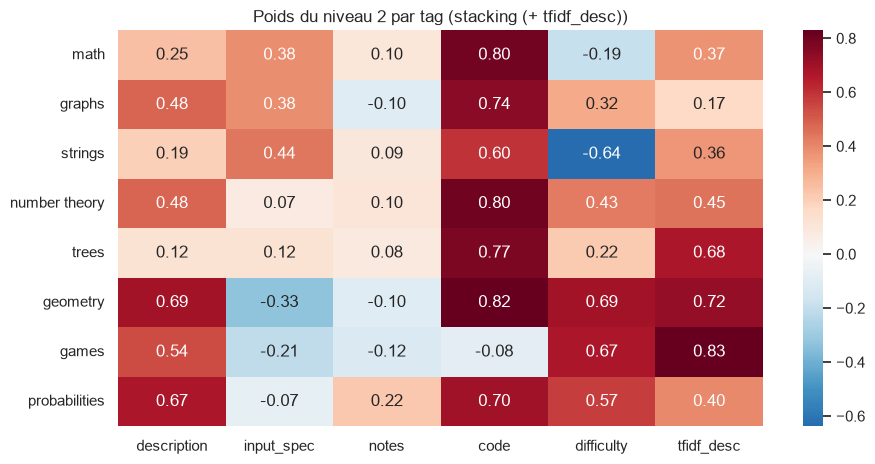

In [14]:
best = models[BEST_MODEL]
weights = pd.DataFrame([meta.coef_[0] for meta in best.meta_models_], index=TAGS, columns=best.names)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.heatmap(weights, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title=f"Poids du niveau 2 par tag ({BEST_MODEL})")
plt.tight_layout()
plt.show()

## 5. Évaluation finale sur le test, et comparaison à un LLM

**LLM zero-shot** : `gemini-3.1-flash-lite` reçoit les mêmes colonnes (énoncé, spécification d'entrée, notes,
difficulté, code) et la définition des 8 tags, et répond en JSON. Aucun entraînement. Ses prédictions sur le test ont
été calculées une fois et sont relues depuis `data/llm/` (aucun appel ici).

In [15]:
LLM = "LLM gemini-3.1-flash-lite (zero-shot)"
if LLM_PREDICTIONS_PATH.exists():
    with LLM_PREDICTIONS_PATH.open() as f:
        llm_tags = {record["sample_id"]: set(record["tags"]) for record in map(json.loads, f)}
    # Un exemple sans réponse compte comme « aucun tag »
    predictions[LLM] = np.array([[tag in llm_tags.get(sid, set()) for tag in TAGS] for sid in test_df.index], dtype=int)
    print(f"Prédictions LLM : {len(llm_tags)} / {len(test_df)} exemples")


def global_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "jaccard": jaccard_score(y_true, y_pred, average="samples", zero_division=1),
    }


pd.DataFrame({name: global_metrics(Y_test, pred) for name, pred in predictions.items()}).T.round(3)

Prédictions LLM : 726 / 726 exemples


,micro_f1,macro_f1,hamming_loss,jaccard
toujours oui,0.158,0.149,0.914,0.086
référence (description),0.554,0.612,0.083,0.532
concat (dense),0.618,0.642,0.074,0.588
MLP multimodal,0.610,0.621,0.075,0.577
stacking (dense),0.622,0.646,0.074,0.602
stacking (+ tfidf_desc),0.627,0.647,0.072,0.600
LLM gemini-3.1-flash-lite (zero-shot),0.674,0.753,0.067,0.581


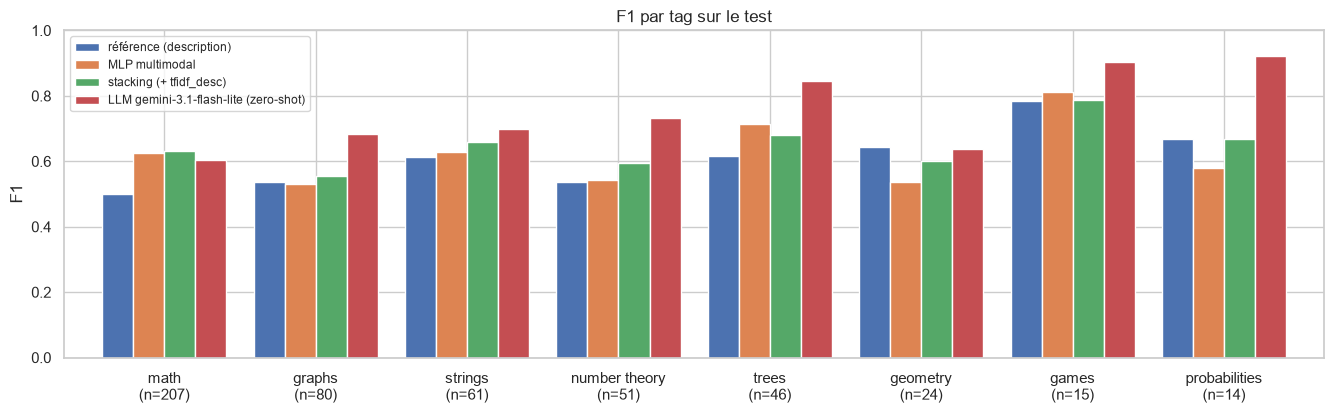

In [16]:
def f1_per_tag(pred: np.ndarray) -> np.ndarray:
    return precision_recall_fscore_support(Y_test, pred, zero_division=0)[2]


key_models = ["référence (description)", "MLP multimodal", BEST_MODEL] + ([LLM] if LLM in predictions else [])
f1_by_tag = pd.DataFrame({name: f1_per_tag(predictions[name]) for name in key_models}, index=TAGS)
support = Y_test.sum(axis=0)

fig, ax = plt.subplots(figsize=(13.5, 4.3))
f1_by_tag.plot.bar(ax=ax, rot=0, width=0.82)
ax.set(title="F1 par tag sur le test", ylabel="F1", ylim=(0, 1))
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(TAGS, support)])
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

In [17]:
# Détail du meilleur modèle entraîné, comparé au plancher « toujours oui »
precision, recall, f1, _ = precision_recall_fscore_support(Y_test, predictions[BEST_MODEL], zero_division=0)
trivial_f1 = f1_per_tag(predictions["toujours oui"])
pd.DataFrame(
    {"précision": precision, "rappel": recall, "f1": f1, "support": support, "f1 toujours oui": trivial_f1, "gain (x)": f1 / trivial_f1},
    index=TAGS,
).round(2)

,précision,rappel,f1,support,f1 toujours oui,gain (x)
math,0.57,0.71,0.63,207,0.44,1.42
graphs,0.52,0.60,0.55,80,0.20,2.80
strings,0.56,0.80,0.66,61,0.16,4.24
number theory,0.55,0.65,0.59,51,0.13,4.53
trees,0.67,0.70,0.68,46,0.12,5.71
geometry,0.46,0.88,0.60,24,0.06,9.38
games,0.72,0.87,0.79,15,0.04,19.46
probabilities,0.62,0.71,0.67,14,0.04,17.62


**Significativité** : même bootstrap apparié qu'au notebook 03.

In [18]:
def bootstrap_diff(pred_a: np.ndarray, pred_b: np.ndarray) -> dict[str, float]:
    rng = np.random.default_rng(SEED)
    diffs = []
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(Y_test), len(Y_test))
        diffs.append(
            f1_score(Y_test[idx], pred_a[idx], average="macro", zero_division=0)
            - f1_score(Y_test[idx], pred_b[idx], average="macro", zero_division=0)
        )
    low, high = np.percentile(diffs, [2.5, 97.5])
    return {"écart moyen": np.mean(diffs), "IC 2,5 %": low, "IC 97,5 %": high, "P(a > b)": np.mean(np.array(diffs) > 0)}


pairs = [
    ("stacking (dense)", "référence (description)"),
    (BEST_MODEL, "référence (description)"),
    (BEST_MODEL, "stacking (dense)"),
    (BEST_MODEL, "MLP multimodal"),
    ("MLP multimodal", "concat (dense)"),
] + ([(LLM, BEST_MODEL)] if LLM in predictions else [])
pd.DataFrame({f"{a} − {b}": bootstrap_diff(predictions[a], predictions[b]) for a, b in pairs}).T.round(3)

,écart moyen,"IC 2,5 %","IC 97,5 %",P(a > b)
stacking (dense) − référence (description),0.034,0.003,0.065,0.985
stacking (+ tfidf_desc) − référence (description),0.035,-0.001,0.073,0.974
stacking (+ tfidf_desc) − stacking (dense),0.001,-0.023,0.028,0.521
stacking (+ tfidf_desc) − MLP multimodal,0.026,-0.004,0.053,0.957
MLP multimodal − concat (dense),-0.021,-0.050,0.005,0.058
LLM gemini-3.1-flash-lite (zero-shot) − stacking (+ tfidf_desc),0.108,0.070,0.151,1.000


## 6. Analyse d'erreurs et latence

In [19]:
pred = predictions[BEST_MODEL]
display(
    pd.DataFrame(
        {"faux positifs": ((pred == 1) & (Y_test == 0)).sum(axis=0), "faux négatifs": ((pred == 0) & (Y_test == 1)).sum(axis=0), "support": support},
        index=TAGS,
    )
)

if LLM in predictions:
    k = TAGS.index("math")
    disagree = predictions[LLM][:, k] != pred[:, k]
    stacking_right = (pred[disagree, k] == Y_test[disagree, k]).sum()
    print(f"Désaccords sur 'math' : {disagree.sum()} | le stacking a raison {stacking_right} fois, le LLM {disagree.sum() - stacking_right} fois")

for kind, tag in [("faux négatifs", "math"), ("faux positifs", "graphs")]:
    k = TAGS.index(tag)
    mask = (pred[:, k] == 0) & (Y_test[:, k] == 1) if kind == "faux négatifs" else (pred[:, k] == 1) & (Y_test[:, k] == 0)
    print(f"\n=== {tag} : {kind} ===")
    for sid, row in test_df[mask].head(2).iterrows():
        print(f"  [{sid}] tags={list(row['tags'])} -> {row['prob_desc_description'][:150]}...")

,faux positifs,faux négatifs,support
math,112,60,207
graphs,45,32,80
strings,39,12,61
number theory,27,18,51
trees,16,14,46
geometry,25,3,24
games,5,2,15
probabilities,6,4,14


Désaccords sur 'math' : 168 | le stacking a raison 110 fois, le LLM 58 fois

=== math : faux négatifs ===
  [40] tags=['number theory', 'bitmasks', 'math', 'strings'] -> You are given two strings $$$s$$$ and $$$t$$$, both consisting of exactly $$$k$$$ lowercase Latin letters, $$$s$$$ is lexicographically less than $$$t...
  [161] tags=['implementation', 'probabilities', 'math'] -> Vasya and Kolya play a game with a string, using the following rules. Initially, Kolya creates a string s, consisting of small English letters, and un...

=== graphs : faux positifs ===
  [64] tags=['dfs and similar'] -> Fox Ciel is playing a mobile puzzle game called "Two Dots". The basic levels are played on a board of size n × m cells, like this:Each cell contains a...
  [81] tags=['implementation'] -> The research center Q has developed a new multi-core processor. The processor consists of n cores and has k cells of cache memory. Consider the work o...


**Latence** : temps pour prédire un exercice de bout en bout (3 encodages Sentence-BERT, 1 encodage UniXcoder,
TF-IDF, stacking et seuils), à partir des textes déjà normalisés. Contrainte du sujet : < 10 s par exemple.

In [20]:
start = time.perf_counter()
text_encoder = SentenceTransformer(TEXT_MODEL, device=device)
code_encoder = SentenceTransformer(CODE_MODEL, device=device)
code_encoder.max_seq_length = CODE_MAX_TOKENS
print(f"Chargement des encodeurs : {time.perf_counter() - start:.1f} s (une seule fois)")


def encode_text(text: str) -> np.ndarray:
    return text_encoder.encode([text], normalize_embeddings=True)


def predict_one(row: pd.Series) -> np.ndarray:
    example = {
        "description": encode_text(row["text_clean"]),
        "input_spec": encode_text(row["input_spec_clean"]),
        "notes": encode_text(row["notes_clean"]),
        "code": code_encoder.encode([row["source_code"]], normalize_embeddings=True),
        "difficulty": np.array([[row["difficulty"]]], dtype=float),
        "tfidf_desc": np.array([row["text_lemma"]]),
        "tfidf_code": np.array([row["source_code"]]),
    }
    return (best.predict_proba(example) >= thresholds[BEST_MODEL]).astype(int)


predict_one(test_df.iloc[0])  # échauffement
latencies = []
for i in range(50):
    start = time.perf_counter()
    predict_one(test_df.iloc[i])
    latencies.append(time.perf_counter() - start)
print(f"Latence par exemple : médiane {np.median(latencies) * 1000:.0f} ms, max {np.max(latencies) * 1000:.0f} ms")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11691.48it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 54030.72it/s]

Chargement des encodeurs : 2.1 s (une seule fois)


Latence par exemple : médiane 60 ms, max 118 ms


## Synthèse

1. **La multimodalité paie** : passer de la description seule au stacking (embeddings + difficulté + TF-IDF de
   description) améliore nettement le Macro-F1 sur le test (voir tableau de la section 5).
2. **Le code (UniXcoder) est la deuxième source la plus utile** : retirer le code fait perdre le plus après la
   description (ablation), et il pèse fortement au niveau 2, en particulier pour `math`, dont le raisonnement se lit
   dans la solution plutôt que dans l'énoncé.
3. **La TF-IDF de description complète les embeddings** (petit gain en CV) ; `notes` et `tfidf_code` n'apportent rien.
   Un **MLP sur les mêmes blocs** (moyenne de 5 graines) ne fait pas mieux que les modèles linéaires : 0,658 de Macro-AP
   en CV et 0,621 de Macro-F1 sur le test, contre 0,647 pour le stacking.
4. **LLM zero-shot** : meilleur en Macro-F1, surtout sur les tags rares et conceptuels, mais il sur-étiquette et fait
   moins bien que le stacking sur `math`, dont la convention d'annotation de Codeforces s'apprend des données.
5. **Contraintes respectées** : modèle local, déterministe, gratuit à l'usage, et prédiction en moins de 100 ms par
   exemple, très loin de la limite de 10 s.

**Pistes** : retirer `notes` (un encodage de moins à l'inférence) ; régler les seuils sur les prédictions out-of-fold
(~4 100 exemples) plutôt que sur val seul (725), pour stabiliser les tags rares.